# clone — GitHub 방식: 고장 종류 + RUL 예측

**주제 변경:** 냉각계통의 고장 유형을 구분하고 고장까지 남은 시간을 예측합니다. M01 10대, 원시 데이터 140초 집계, 마지막 고장 사이클 평가입니다. 24시간 조기경보와 다른 문제입니다.

[설정과 차이](README.md) · [상세 보고서](results/REPORT.md) · [원본 GitHub](https://github.com/ki-seoultech/PHM2018-Ion-Mill-Etch-3Stage-Predictive-Maintenance)

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'models/clone/github_rul/results/rul_metrics.csv').exists())
clone = root / 'models/clone/github_rul'
classifier = json.loads((clone / 'results/classifier.json').read_text(encoding='utf-8'))
metrics = pd.read_csv(clone / 'results/rul_metrics.csv')
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
display(pd.read_csv(clone / 'results/preparation.csv'))

,tool,raw_rows,shutter1_rows,sensor_file,sensor_bytes,target_file,target_bytes,F1_bins,F2_bins,F3_bins,classifier_bins
0,01_M01,3124704,1486930,data\raw\phm_data_challenge_2018\train\01_M01_...,1107918027,data\raw\phm_data_challenge_2018\train\train_t...,103340393,51936,23657,53530,53530
1,02_M01,2865625,1606130,data\raw\phm_data_challenge_2018\train\02_M01_...,1012645089,data\raw\phm_data_challenge_2018\train\train_t...,100217241,52958,41654,51106,52963
2,03_M01,3432217,2076524,data\raw\phm_data_challenge_2018\train\03_M01_...,1210432632,data\raw\phm_data_challenge_2018\train\train_t...,92642912,70947,0,62999,70950
3,04_M01,5097901,2880749,data\raw\phm_data_challenge_2018\train\04_M01_...,1799780895,data\raw\phm_data_challenge_2018\train\train_t...,98515587,884,12586,73629,73629
4,05_M01,4779554,2695559,data\raw\phm_data_challenge_2018\train\05_M01_...,1709211881,data\raw\phm_data_challenge_2018\train\train_t...,156993904,86084,89069,63490,89072
5,06_M01,3812209,2325744,data\raw\phm_data_challenge_2018\train\06_M01_...,1357815302,data\raw\phm_data_challenge_2018\train\train_t...,128541508,83967,34574,83037,83968
6,07_M01,5301166,2891669,data\raw\phm_data_challenge_2018\train\07_M01_...,1872457925,data\raw\phm_data_challenge_2018\train\train_t...,183148620,77275,106279,101650,106282
7,08_M01,3716092,2376819,data\raw\phm_data_challenge_2018\train\08_M01_...,1332300485,data\raw\phm_data_challenge_2018\train\train_t...,139530057,81285,82055,81283,82079
8,09_M01,4565604,2535459,data\raw\phm_data_challenge_2018\train\09_M01_...,1615745448,data\raw\phm_data_challenge_2018\train\train_t...,150798038,94171,54745,81422,94195
9,10_M01,3166038,1840167,data\raw\phm_data_challenge_2018\train\10_M01_...,1128599570,data\raw\phm_data_challenge_2018\train\train_t...,70499383,9476,9478,57925,57927


## 1. 고장 유형 분류

XGBoost + SMOTE, **Macro F1 0.9539**, 정확도 96.09%. **고장까지 약 3.9시간 이내인 구간의 조건부 원인 분류**이며 정상/위험 탐지 성능은 아닙니다.

In [2]:
display(pd.DataFrame(classifier['classification_report']).T.round(4))
matrix = pd.DataFrame(classifier['confusion_matrix'], index=['실제 과다', '실제 누설', '실제 저하'], columns=['예측 과다', '예측 누설', '예측 저하'])
display(matrix)

,precision,recall,f1-score,support
압력 과다,0.9429,0.9925,0.9670,266.0000
누설,1.0000,0.8750,0.9333,72.0000
압력 저하,0.9683,0.9545,0.9614,352.0000
accuracy,0.9609,0.9609,0.9609,0.9609
macro avg,0.9704,0.9407,0.9539,690.0000
weighted avg,0.9618,0.9609,0.9606,690.0000


,예측 과다,예측 누설,예측 저하
실제 과다,264,0,2
실제 누설,0,63,9
실제 저하,16,0,336


## 2. RUL 결과 — 모든 평가 행

정답은 14,000~15,000초로 상한을 적용했습니다. 항상 상한 예측과 학습 평균 예측도 비교합니다. 원본 방식 isotonic은 사이클 전체 예측을 보는 **오프라인 보정**입니다.

In [3]:
columns = ['fault_name', 'model', 'mae_seconds', 'rmse_seconds', 'r2', 'source_score', 'rows']
display(metrics.loc[metrics.scope.eq('all_capped'), columns].round(3))

,fault_name,model,mae_seconds,rmse_seconds,r2,source_score,rows
0,압력 과다,always_cap,27.118,520.939,-0.003,328333.315,56322
2,압력 과다,training_mean,58.228,520.250,-0.000,327557.487,56322
4,압력 과다,HGBM,386.489,1271.965,-4.978,315471.769,56322
6,압력 과다,GRU,2562.257,2721.665,-26.370,223096.878,56322
8,압력 과다,dynamic_ensemble,905.517,1451.221,-6.782,272044.632,56322
10,압력 과다,offline_isotonic_ensemble,904.619,1297.201,-5.218,265603.792,56322
12,누설,always_cap,3.858,180.501,-0.000,79752.728,129336
14,누설,training_mean,28.785,181.689,-0.014,79604.407,129336
16,누설,HGBM,635.253,1531.963,-71.067,76451.779,129336
18,누설,LSTM,2095.037,2155.783,-141.709,67108.277,129336


## 3. 고장 가까이에서의 RUL 결과

실제 남은 시간이 상한보다 짧은 평가 구간만 따로 봅니다.

In [4]:
display(metrics.loc[metrics.scope.eq('near_failure_only'), columns].round(3))

,fault_name,model,mae_seconds,rmse_seconds,r2,source_score,rows
1,압력 과다,always_cap,7038.406,8392.587,-2.371,328333.315,217
3,압력 과다,training_mean,7007.215,8366.312,-2.350,327556.025,217
5,압력 과다,HGBM,6601.331,7972.732,-2.042,315454.859,217
7,압력 과다,GRU,4449.901,5542.261,-0.470,222977.681,217
9,압력 과다,dynamic_ensemble,5572.687,6833.182,-1.234,272003.229,217
11,압력 과다,offline_isotonic_ensemble,5480.482,6684.056,-1.138,265562.415,217
13,누설,always_cap,5543.889,6842.544,-1.911,79752.728,90
15,누설,training_mean,5518.927,6822.336,-1.894,79601.724,90
17,누설,HGBM,4659.586,6061.713,-1.284,76383.808,90
19,누설,LSTM,4120.385,5559.764,-0.922,66883.271,90


## 4. 고장별 실제·예측 추세

각 고장의 평가 사이클 중 고장 직전 행이 가장 많은 사이클 하나를 표시합니다.

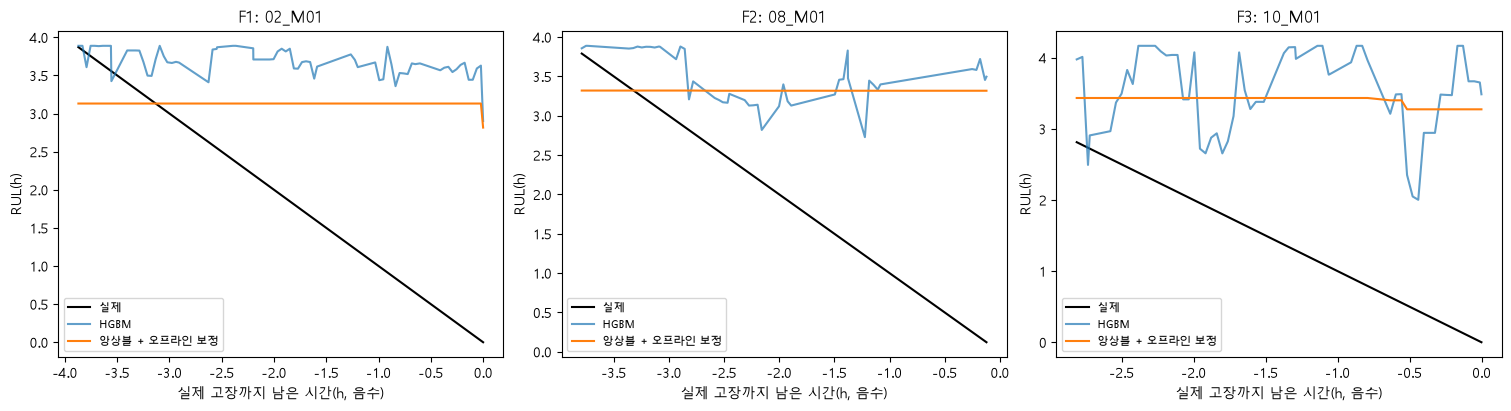

In [5]:
figure, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for axis, mode in zip(axes, ['F1', 'F2', 'F3']):
    metadata = json.loads((clone / 'artifacts' / mode / 'metadata.json').read_text(encoding='utf-8'))
    predictions = pd.read_csv(clone / 'artifacts' / mode / 'predictions.csv')
    near = predictions[predictions[metadata['target']] < metadata['cap_seconds']]
    if near.empty:
        axis.text(.5, .5, '고장 직전 평가 행 없음', ha='center')
        continue
    episode = near.episode_id.value_counts().index[0]
    selected = near[near.episode_id.eq(episode)].sort_values('time')
    relative_time = -selected[metadata['target']] / 3600
    axis.plot(relative_time, selected.target_capped / 3600, color='black', label='실제')
    axis.plot(relative_time, selected.HGBM / 3600, label='HGBM', alpha=.7)
    axis.plot(relative_time, selected.offline_isotonic_ensemble / 3600, label='앙상블 + 오프라인 보정')
    axis.set(title=f'{mode}: {selected.PhysicalTool.iloc[0]}', xlabel='실제 고장까지 남은 시간(h, 음수)', ylabel='RUL(h)')
    axis.legend(fontsize=8)
figure.savefig(clone / 'results/rul_examples.png', dpi=150)
plt.show()

## 5. DL 학습 이력

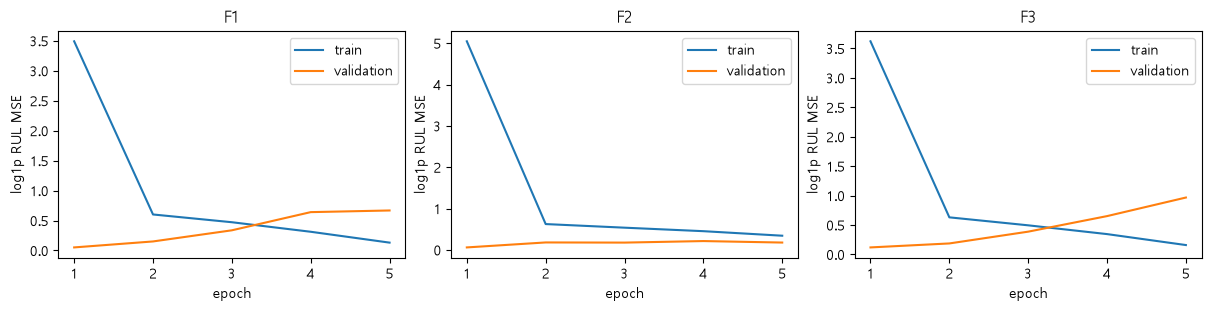

In [6]:
figure, axes = plt.subplots(1, 3, figsize=(12, 3), constrained_layout=True)
for axis, mode in zip(axes, ['F1', 'F2', 'F3']):
    history = pd.read_csv(clone / 'artifacts' / mode / 'training_history.csv')
    axis.plot(history.epoch, history.loss, label='train')
    axis.plot(history.epoch, history.val_loss, label='validation')
    axis.set(title=mode, xlabel='epoch', ylabel='log1p RUL MSE')
    axis.legend()
figure.savefig(clone / 'results/training_curves.png', dpi=150)
plt.show()

## 해석 범위

원본과 같은 오프라인 문제로 바꾼 실행입니다. 고장 사이클 구분·backward fill·사이클 전체 isotonic에는 미래 정보가 있으므로 실시간 사전경보 성능으로 해석하지 않습니다. 원본의 비공개 labeled CSV 대신 공식 원시 센서·TTF를 재구성했고, 결측 TTF를 잘못된 고장 유형으로 고르는 argmin 동작은 수정했습니다. 입력에는 TTF를 넣지 않았습니다. [상세 결과와 차이](results/REPORT.md)를 함께 확인하세요.